# Register Fault Injection — Resilience Analysis
**Model:** Fashion-MNIST Image Classification (INT8 quantized TFLite)  
**Target:** RISC-V registers (transient bit-flip)  
**Campaign:** `registerfi_image_classification_fashsion_mnist_transient`  
**Sampling:** Stratified per operator — 95% confidence, 5% margin

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path(".")  # notebook lives inside the run directory

SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50",
    "Good": "#81C784",
    "Acceptable": "#FFC107",
    "Warning": "#FF9800",
    "Critical": "#F44336",
    "Crash": "#B71C1C",
}

CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

## 1. Data Loading

In [19]:
df = pd.read_csv(RUN_DIR / "classified_results.csv")
pop = pd.read_csv(RUN_DIR / "register_population.csv")
sel = pd.read_csv(RUN_DIR / "selected_register_faults.csv")
sel_by_layer = pd.read_csv(RUN_DIR / "selected_register_faults_by_layer.csv")
pop_by_op = pd.read_csv(RUN_DIR / "register_population_by_operator.csv")
operators = pd.read_csv(RUN_DIR / "all_operator_instances.csv")

import json
with open(RUN_DIR / "run_manifest.json") as f:
    manifest = json.load(f)

# Merge register + operator metadata from selected_register_faults into classified results
reg_meta = sel[["fault_id", "register_name", "register_class", "register_id",
                "op_index", "op_name", "bit_index"]].drop_duplicates("fault_id")
df = df.merge(reg_meta, on="fault_id", how="left", suffixes=("", "_meta"))

# Ensure register_name and register_class columns are populated
if "register_name_meta" in df.columns:
    df["register_name"] = df["register_name"].fillna(df["register_name_meta"])
if "register_class" not in df.columns and "register_class_meta" in df.columns:
    df["register_class"] = df["register_class_meta"]

# Fill missing operator_name / operator_index / bit_index from sel metadata
df["operator_name"] = df["operator_name"].fillna(df["op_name"])
df["operator_index"] = df["operator_index"].fillna(df["op_index"])
if "bit_index_meta" in df.columns:
    df["bit_index"] = df["bit_index"].fillna(df["bit_index_meta"])

print(f"Total classified results : {len(df):,}")
print(f"Unique faults injected   : {df['fault_id'].nunique():,}")
print(f"Images per fault         : {len(df) // df['fault_id'].nunique()}")
print(f"Population size          : {len(pop):,}")
print(f"Operators targeted       : {df['operator_index'].nunique()}")
print(f"Registers targeted       : {df['register_name'].nunique()}")
print(f"Fault model              : {manifest.get('campaign_type', 'register')}")
print(f"Fault duration           : {manifest.get('fault_duration', 'transient')}")
df.head(3)

Total classified results : 278,000
Unique faults injected   : 2,780
Images per fault         : 100
Population size          : 9,920
Operators targeted       : 10
Registers targeted       : 31
Fault model              : register
Fault duration           : permanent


,event,phase,mode,fault_model,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,...,samples,golden_pred_class_ref,golden_top1_prob_ref,fault_class,register_name_meta,register_class,register_id_meta,op_index,op_name,bit_index_meta
0,result,fault,fault,register,3.0,0.0,NaN,-1.0,0.0,NaN,...,NaN,0.0,0.109375,Crash,ra,caller_saved,0,0,CONV_2D,3
1,result,fault,fault,register,3.0,1.0,NaN,-1.0,0.0,NaN,...,NaN,0.0,0.101562,Crash,ra,caller_saved,0,0,CONV_2D,3
2,result,fault,fault,register,3.0,2.0,NaN,-1.0,0.0,NaN,...,NaN,0.0,0.101562,Crash,ra,caller_saved,0,0,CONV_2D,3


## 2. Overall Fault Classification Distribution

,Count,Percentage (%)
fault_class,,
Masked,99600.0,35.83
Good,2256.0,0.81
Acceptable,9269.0,3.33
Warning,2686.0,0.97
Critical,17293.0,6.22
Crash,146896.0,52.84
TOTAL,278000.0,100.00


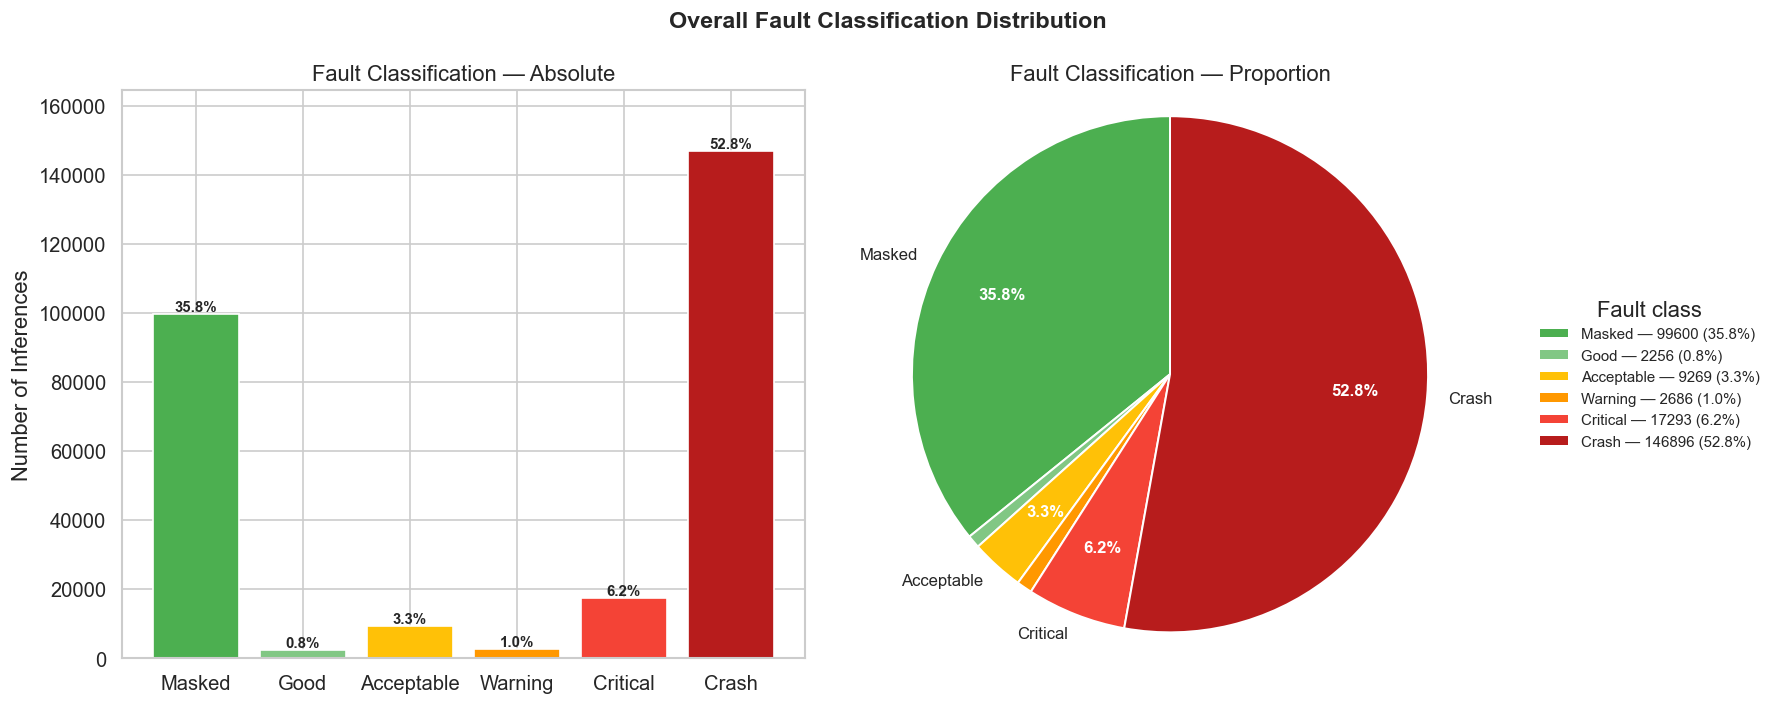

In [20]:
fc_counts = df["fault_class"].value_counts()
fc_ordered = fc_counts.reindex(SEVERITY_ORDER).dropna().astype(int)
fc_pct = fc_ordered / len(df) * 100

summary_table = pd.DataFrame({"Count": fc_ordered, "Percentage (%)": fc_pct.round(2)})
summary_table.loc["TOTAL"] = [len(df), 100.0]
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
colors = [SEVERITY_COLORS.get(c, "#999") for c in fc_ordered.index]
bars = axes[0].bar(fc_ordered.index, fc_ordered.values, color=colors, edgecolor="white")
for bar, pct in zip(bars, fc_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Number of Inferences")
axes[0].set_title("Fault Classification — Absolute")
axes[0].margins(y=0.12)

# Pie chart — rótulos só para fatias >= 3%, demais vão só na legenda
THRESH = 3.0  # %

def _autopct(pct):
    return f"{pct:.1f}%" if pct >= THRESH else ""

pie_labels = [name if pct >= THRESH else "" for name, pct in zip(fc_ordered.index, fc_pct.values)]

wedges, texts, autotexts = axes[1].pie(
    fc_ordered.values,
    labels=pie_labels,
    colors=colors,
    autopct=_autopct,
    startangle=90,
    pctdistance=0.72,
    labeldistance=1.08,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=10),
)
for t in autotexts:
    t.set_fontweight("bold")
    t.set_color("white")

axes[1].set_title("Fault Classification — Proportion")
axes[1].axis("equal")

# Legenda completa (inclui fatias pequenas omitidas do gráfico)
legend_labels = [f"{name} — {cnt} ({pct:.1f}%)"
                 for name, cnt, pct in zip(fc_ordered.index, fc_ordered.values, fc_pct.values)]
axes[1].legend(
    wedges, legend_labels,
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9,
    frameon=False,
)

fig.suptitle("Overall Fault Classification Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_overall_classification.png", bbox_inches="tight")
plt.show()

## 3. Resilience per Register

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
register_name,,,,,,,,
a1,8800,92,162,11,569,7898,0.9622,0.9634
ra,8800,802,0,0,0,7998,0.9089,0.9089
a0,9500,931,4,0,5,8560,0.9016,0.9016
a2,10100,1152,17,34,89,8797,0.8798,0.8832
s0,8800,542,18,552,280,7385,0.8710,0.9338
a5,9100,750,489,7,1135,6564,0.8460,0.8468
s6,9700,1894,78,5,437,7241,0.7915,0.7921
s8,9400,1683,59,287,614,6699,0.7780,0.8085
s3,8400,1079,653,38,1039,5490,0.7773,0.7818


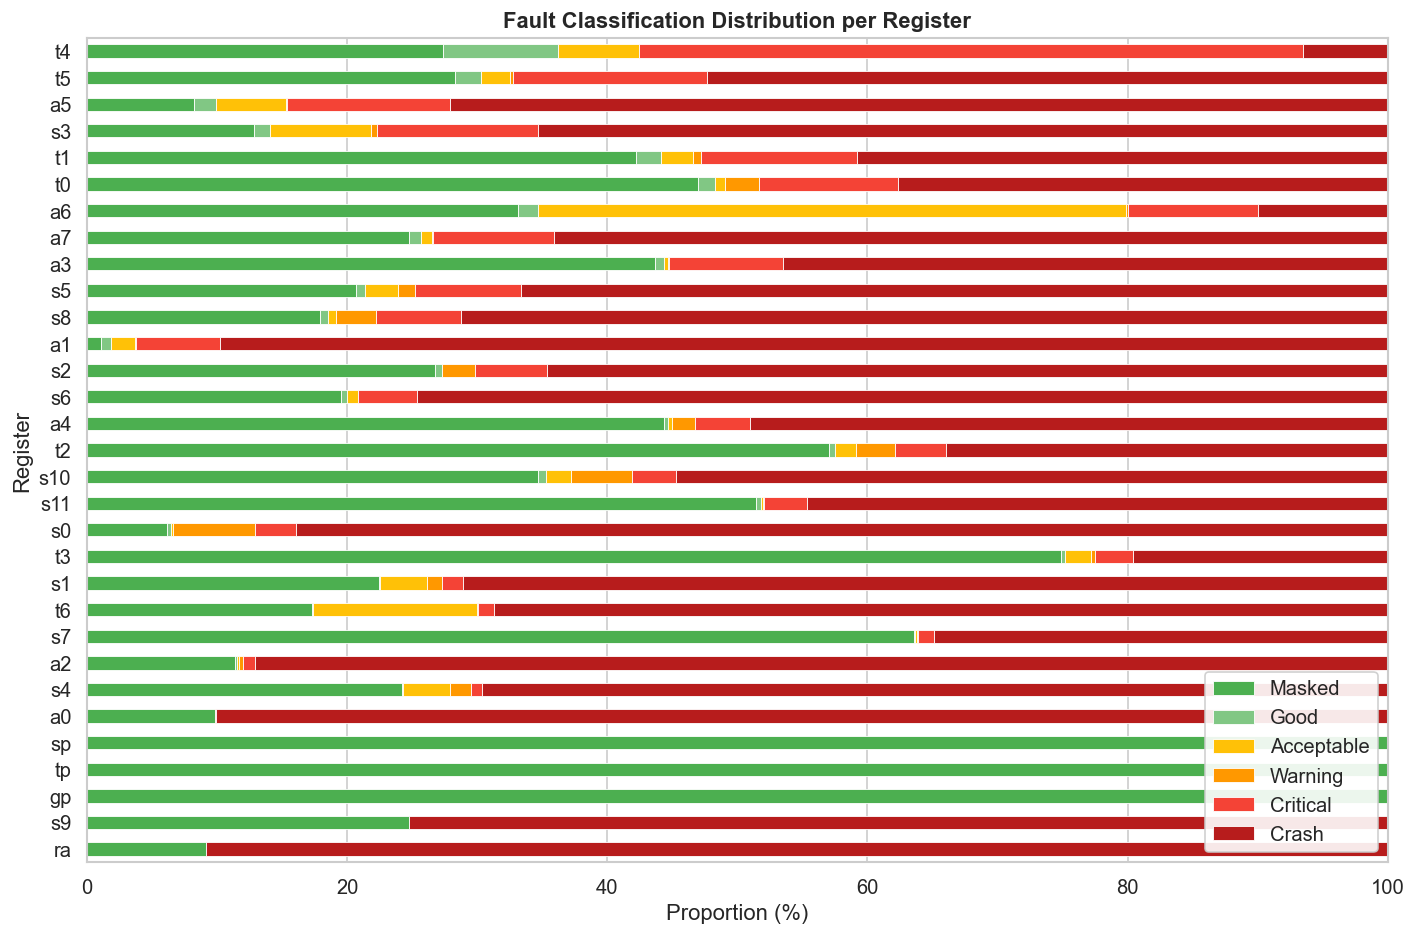

In [21]:
# Aggregate fault class distribution per register
reg_fc = df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
reg_fc = reg_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
reg_fc["total"] = reg_fc.sum(axis=1)
reg_fc["critical_rate"] = (reg_fc.get("Critical", 0) + reg_fc.get("Crash", 0)) / reg_fc["total"]
reg_fc["degraded_rate"] = reg_fc[[c for c in DEGRADED_SET if c in reg_fc.columns]].sum(axis=1) / reg_fc["total"]
reg_fc = reg_fc.sort_values("critical_rate", ascending=False)

display(reg_fc[["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]].round(4))

# Stacked bar — percentage per register
reg_pct = reg_fc[SEVERITY_ORDER].div(reg_fc["total"], axis=0) * 100
reg_pct_sorted = reg_pct.sort_values("Critical", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
reg_pct_sorted.plot.barh(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white", linewidth=0.5,
)
ax.set_xlabel("Proportion (%)")
ax.set_ylabel("Register")
ax.set_title("Fault Classification Distribution per Register", fontweight="bold")
ax.legend(loc="lower right", framealpha=0.9)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_register.png", bbox_inches="tight")
plt.show()

## 4. Resilience per Register Class
Registers are grouped by their RISC-V ABI classification: **caller-saved** (temporary), **callee-saved** (preserved), and **special** (sp, gp, tp, ra).

fault_class,Masked,Good,Acceptable,Warning,Critical,Crash,total,critical_rate,degraded_rate
register_class,,,,,,,,,
callee_saved,30172,455,1844,1855,4503,69571,108400,0.6833,0.7005
caller_saved,42028,1801,7425,831,12790,77325,142200,0.6337,0.6396
special,27400,0,0,0,0,0,27400,0.0000,0.0000


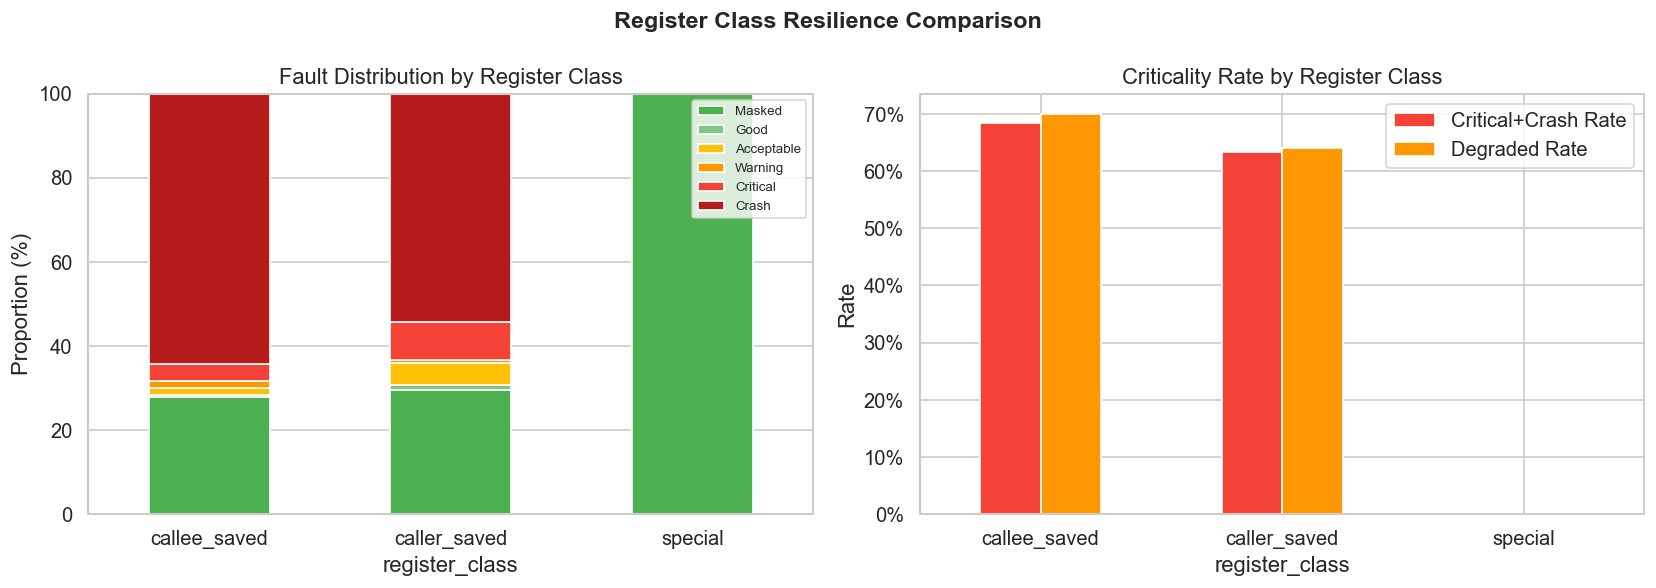

In [22]:
cls_fc = df.groupby("register_class")["fault_class"].value_counts().unstack(fill_value=0)
cls_fc = cls_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
cls_fc["total"] = cls_fc.sum(axis=1)
cls_fc["critical_rate"] = (cls_fc.get("Critical", 0) + cls_fc.get("Crash", 0)) / cls_fc["total"]
cls_fc["degraded_rate"] = cls_fc[[c for c in DEGRADED_SET if c in cls_fc.columns]].sum(axis=1) / cls_fc["total"]

display(cls_fc.round(4))

cls_pct = cls_fc[SEVERITY_ORDER].div(cls_fc["total"], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cls_pct.plot.bar(
    stacked=True, ax=axes[0],
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
axes[0].set_ylabel("Proportion (%)")
axes[0].set_title("Fault Distribution by Register Class")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(axis="x", rotation=0)

# Critical + Crash rate comparison
cls_crit = cls_fc[["critical_rate", "degraded_rate"]].copy()
cls_crit.columns = ["Critical+Crash Rate", "Degraded Rate"]
cls_crit.plot.bar(ax=axes[1], color=["#F44336", "#FF9800"], edgecolor="white")
axes[1].set_ylabel("Rate")
axes[1].set_title("Criticality Rate by Register Class")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Register Class Resilience Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_register_class_resilience.png", bbox_inches="tight")
plt.show()

## 5. Resilience per Operator (Layer)

In [23]:
df.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'operator_index',
       'operator_name', 'register_id', 'register_name', 'time_slot_index',
       'time_slot_count', 'delay_us', 'bit_index', 'mean_duration_us',
       'samples', 'golden_pred_class_ref', 'golden_top1_prob_ref',
       'fault_class', 'register_name_meta', 'register_class',
       'register_id_meta', 'op_index', 'op_name', 'bit_index_meta'],
      dtype='str')

In [24]:
df['operator_index'].value_counts()

operator_index
0.0     27800
1.0     27800
3.0     27800
4.0     27800
6.0     27800
7.0     27800
13.0    27800
14.0    27800
15.0    27800
16.0    27800
Name: count, dtype: int64

In [25]:
d = pd.read_csv('results.csv')

C:\Users\ronal\AppData\Local\Temp\ipykernel_12468\1667207595.py:1: DtypeWarning: Columns (0: operator_name) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv('results.csv')


In [26]:
d['operator_name'].value_counts()

operator_name
CONV_2D            6
FULLY_CONNECTED    4
Name: count, dtype: int64

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
CONV_2D,166800,44625,4800,874,9280,105964,0.6909,0.6962
FULLY_CONNECTED,111200,54975,4469,1812,8013,40932,0.4402,0.4564


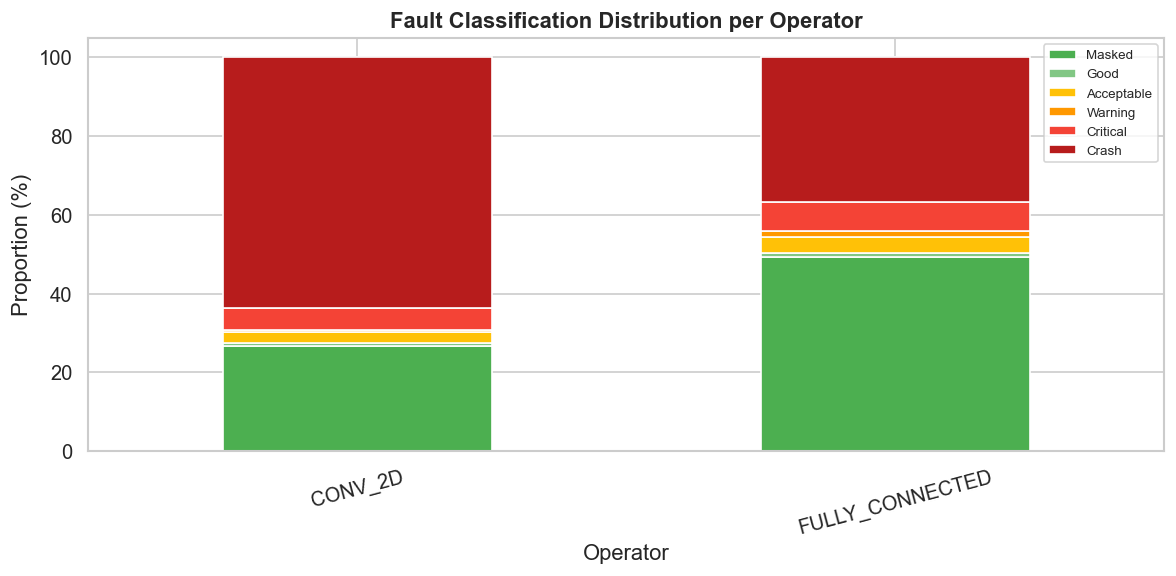

In [27]:
import numpy as np

# Usa apenas o nome real do operador
df["op_label"] = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

op_fc = op_fc.sort_values("critical_rate", ascending=False)

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den, axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator")
ax.set_title("Fault Classification Distribution per Operator", fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 6. Register × Operator Criticality Heatmap

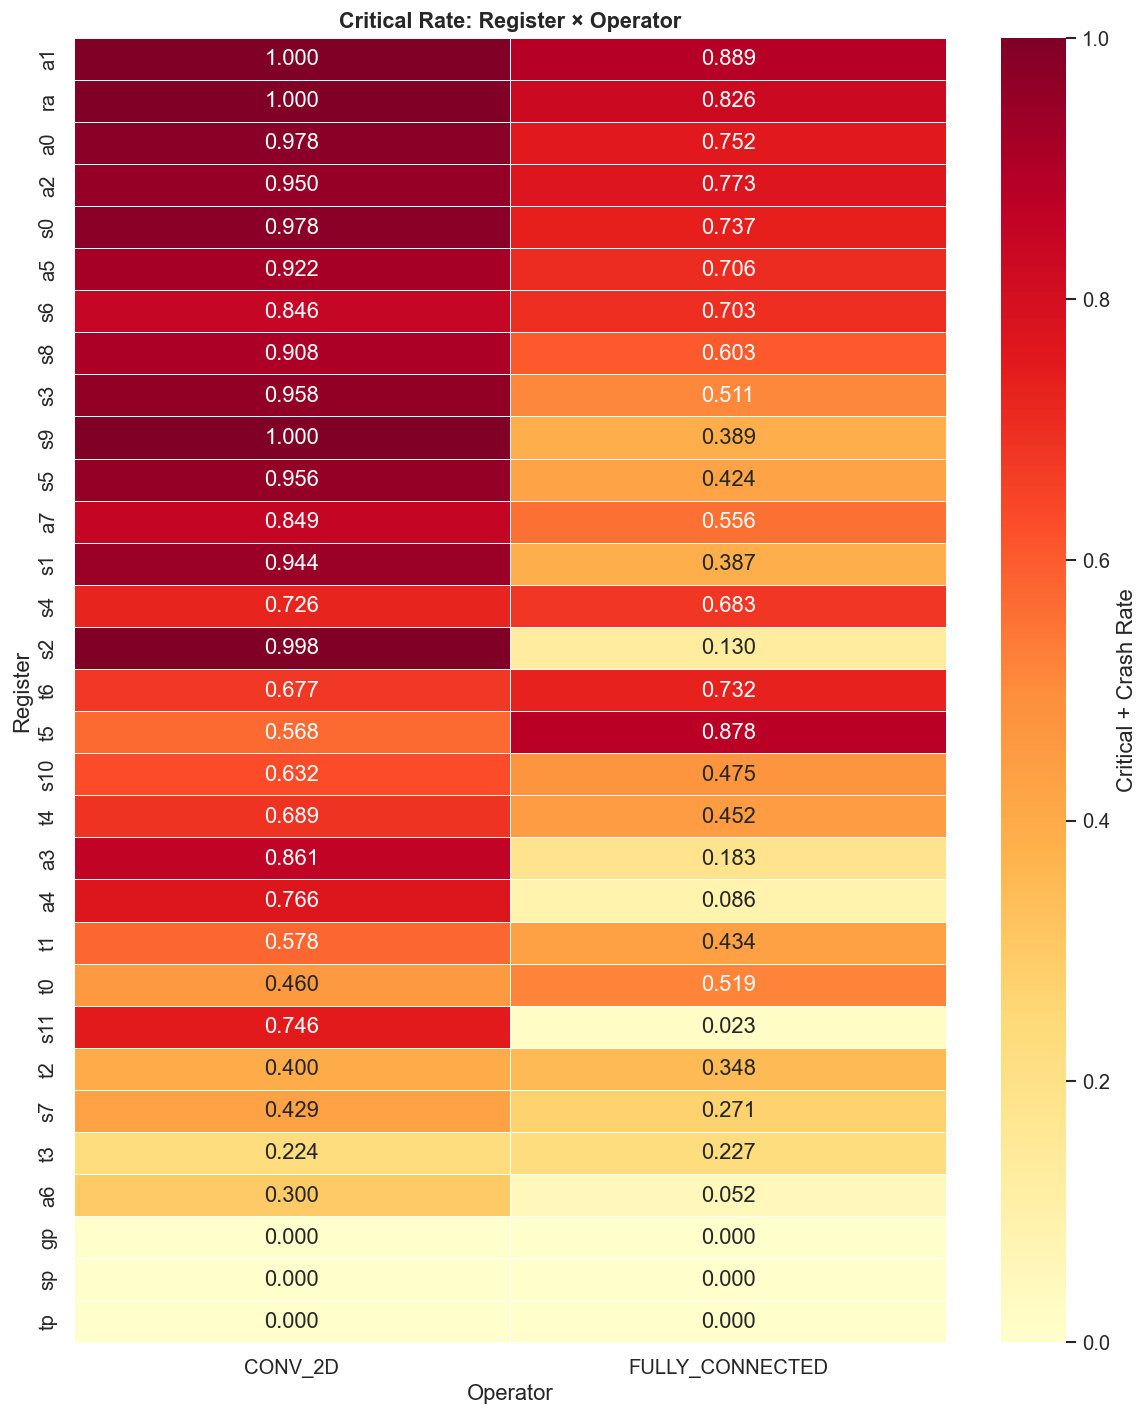

In [28]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)

# Sort registers by overall critical rate
reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=False).index
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

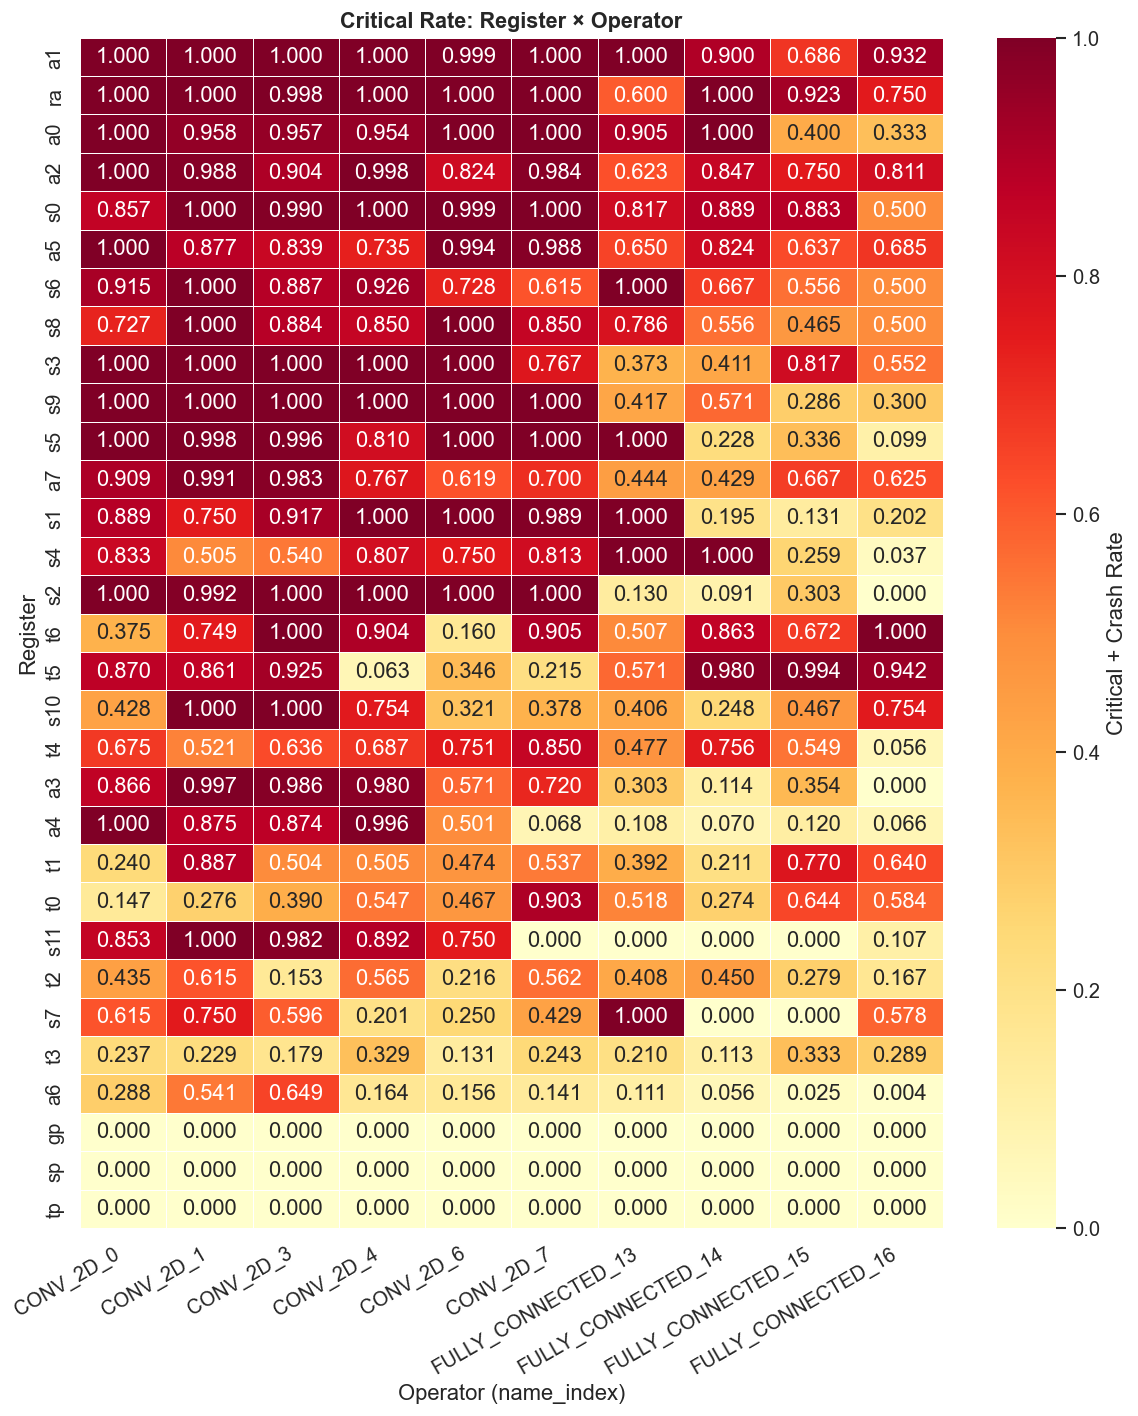

In [29]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Build "operator_name_operator_index" label (e.g. CONV_2D_0, CONV_2D_2)
op_name = (
    df["operator_name"].astype("string").str.strip()
    .replace("", pd.NA).fillna("Unknown")
)
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64").astype("string").fillna("NA")
)
df["op_full"] = op_name + "_" + op_idx

heatmap_data = (
    df.groupby(["register_name", "op_full"])
      .apply(critical_rate)
      .unstack(fill_value=0)
)

# Order columns by numeric operator_index when possible
col_order = sorted(
    heatmap_data.columns,
    key=lambda c: (int(c.rsplit("_", 1)[1]) if c.rsplit("_", 1)[1].isdigit() else 10**9, c),
)
heatmap_data = heatmap_data[col_order]

# Sort registers by overall critical rate
reg_order = (
    df.groupby("register_name").apply(critical_rate)
      .sort_values(ascending=False).index
)
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator (name_index)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,27800,7479,763,177,1637,17553,0.6903,0.6967
1_CONV_2D,27800,5379,741,70,1795,19537,0.7673,0.7699
3_CONV_2D,27800,5814,621,164,1590,19419,0.7557,0.7616
4_CONV_2D,27800,7139,1005,97,1585,17769,0.6962,0.6997
6_CONV_2D,27800,9830,648,195,1327,15606,0.6091,0.6161
7_CONV_2D,27800,8984,1022,171,1346,16080,0.6268,0.6330
13_FULLY_CONNECTED,27800,12489,853,145,1464,12653,0.5078,0.5130
14_FULLY_CONNECTED,27800,13947,903,350,1928,10420,0.4442,0.4568
15_FULLY_CONNECTED,27800,13957,1283,583,3027,8599,0.4182,0.4392


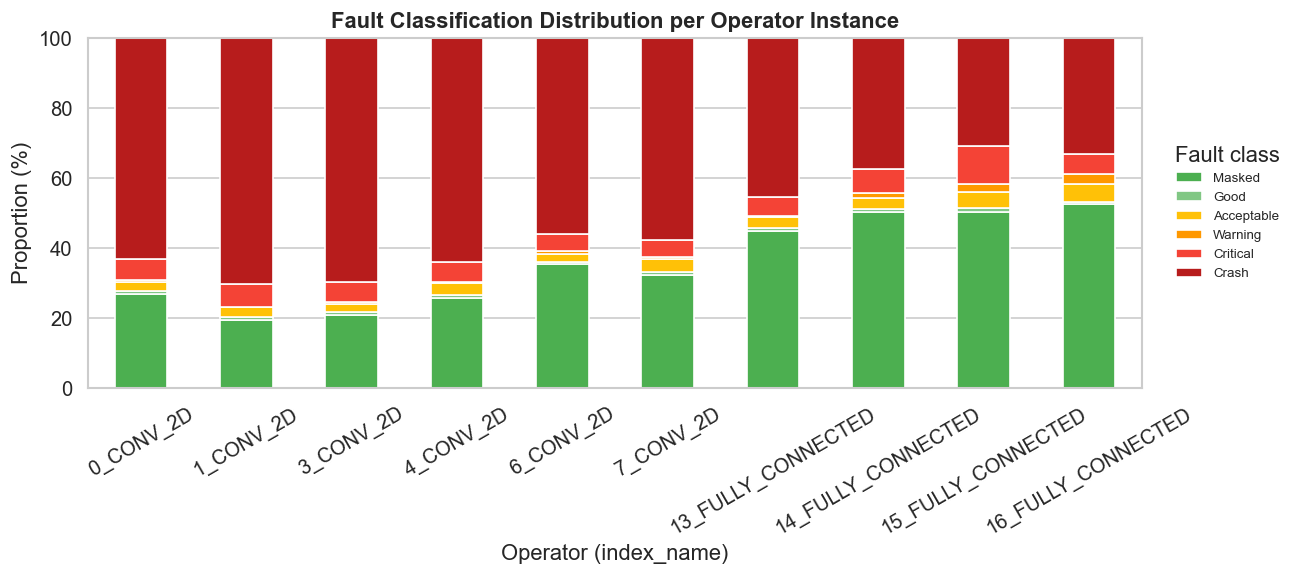

In [30]:
import numpy as np

# Combina operator_index + operator_name para distinguir instâncias do mesmo operador
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)
op_name = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
df["op_label"] = op_idx + "_" + op_name

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

# Ordena por op_index numérico (quando disponível) para manter ordem natural da rede
def _sort_key(label: str):
    head = label.split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

op_fc = op_fc.loc[sorted(op_fc.index, key=_sort_key)]

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den.loc[op_fc.index], axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator (index_name)")
ax.set_title("Fault Classification Distribution per Operator Instance", fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=False,
)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 7. Bit-Position Vulnerability Analysis
Evaluates whether higher-order bits (MSB) lead to more critical failures than lower-order bits (LSB).

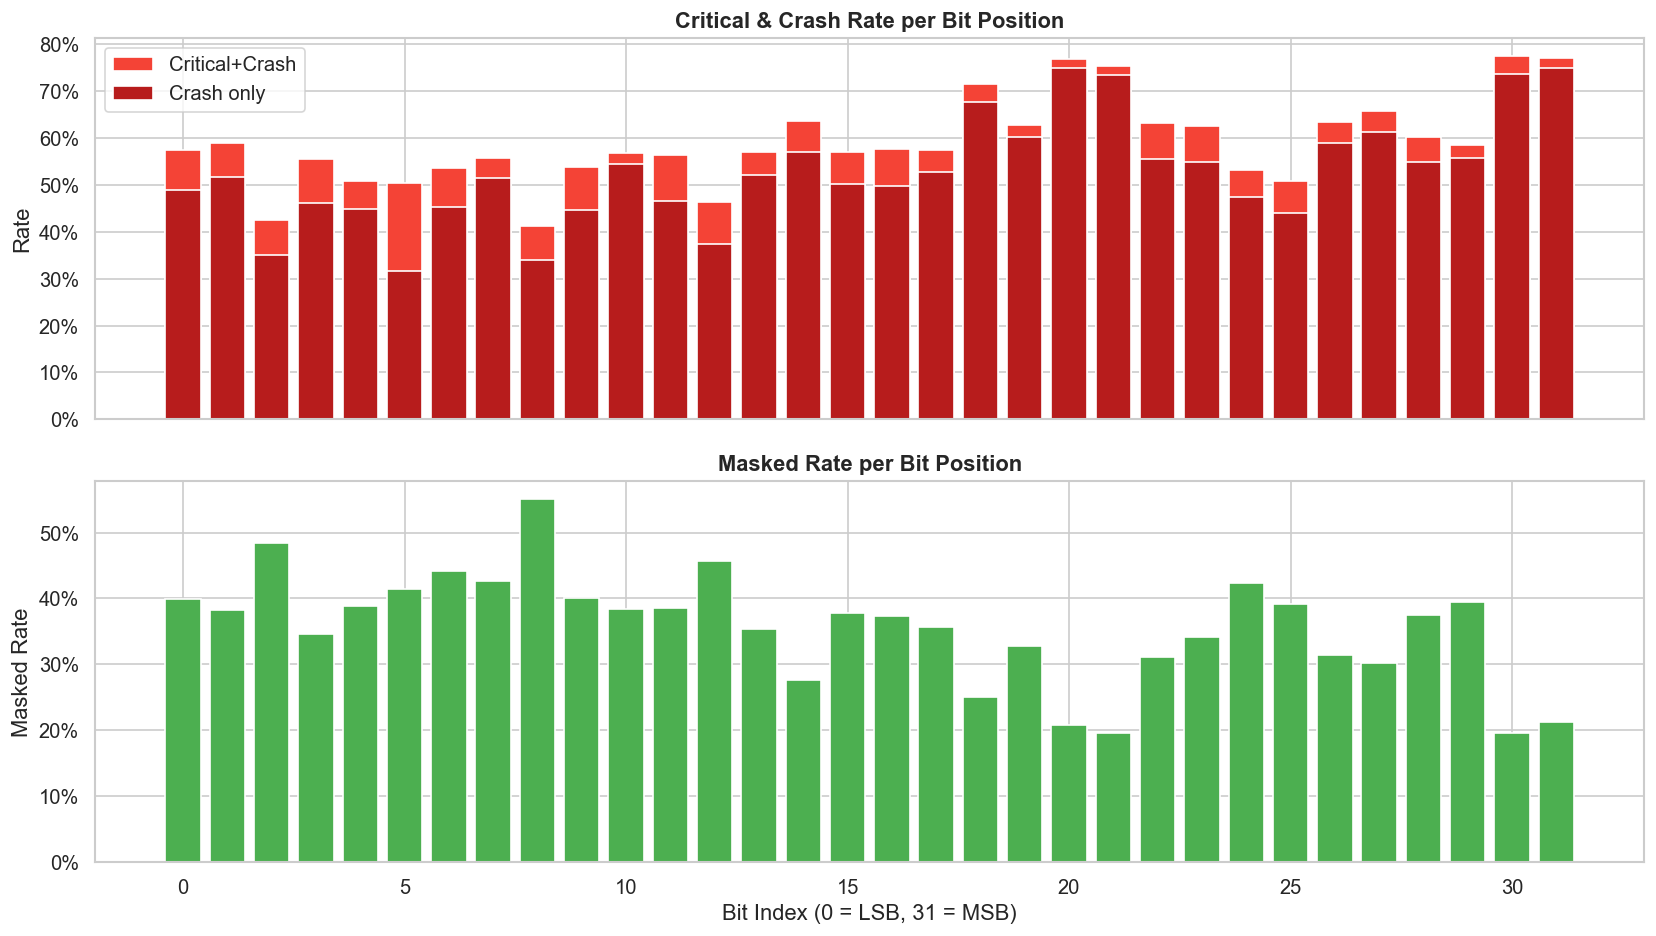

,bit_index,total,critical,degraded,crash,masked,critical_rate,crash_rate,masked_rate
0,0,9000,5164,5219,4394,3587,0.5738,0.4882,0.3986
1,1,9400,5539,5693,4868,3601,0.5893,0.5179,0.3831
2,2,9800,4163,4325,3426,4740,0.4248,0.3496,0.4837
3,3,9000,5007,5254,4157,3121,0.5563,0.4619,0.3468
4,4,9500,4824,5129,4264,3696,0.5078,0.4488,0.3891
5,5,7500,3789,3830,2374,3109,0.5052,0.3165,0.4145
6,6,9700,5194,5236,4392,4277,0.5355,0.4528,0.4409
7,7,8500,4743,4815,4374,3621,0.5580,0.5146,0.4260
8,8,7400,3047,3114,2523,4077,0.4118,0.3409,0.5509
9,9,9500,5116,5213,4235,3809,0.5385,0.4458,0.4009


In [31]:
bit_fc = df.groupby("bit_index").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "degraded": g["fault_class"].isin(DEGRADED_SET).sum(),
        "crash": (g["fault_class"] == "Crash").sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
    })
).reset_index()
bit_fc["bit_index"] = bit_fc["bit_index"].astype(int)
bit_fc["critical_rate"] = bit_fc["critical"] / bit_fc["total"]
bit_fc["crash_rate"] = bit_fc["crash"] / bit_fc["total"]
bit_fc["masked_rate"] = bit_fc["masked"] / bit_fc["total"]
bit_fc = bit_fc.sort_values("bit_index")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(bit_fc["bit_index"], bit_fc["critical_rate"], color="#F44336", label="Critical+Crash")
axes[0].bar(bit_fc["bit_index"], bit_fc["crash_rate"], color="#B71C1C", label="Crash only")
axes[0].set_ylabel("Rate")
axes[0].set_title("Critical & Crash Rate per Bit Position", fontweight="bold")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[1].bar(bit_fc["bit_index"], bit_fc["masked_rate"], color="#4CAF50")
axes[1].set_ylabel("Masked Rate")
axes[1].set_xlabel("Bit Index (0 = LSB, 31 = MSB)")
axes[1].set_title("Masked Rate per Bit Position", fontweight="bold")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability.png", bbox_inches="tight")
plt.show()

display(bit_fc.round(4))

## 8. Bit-Position Vulnerability by Register Class

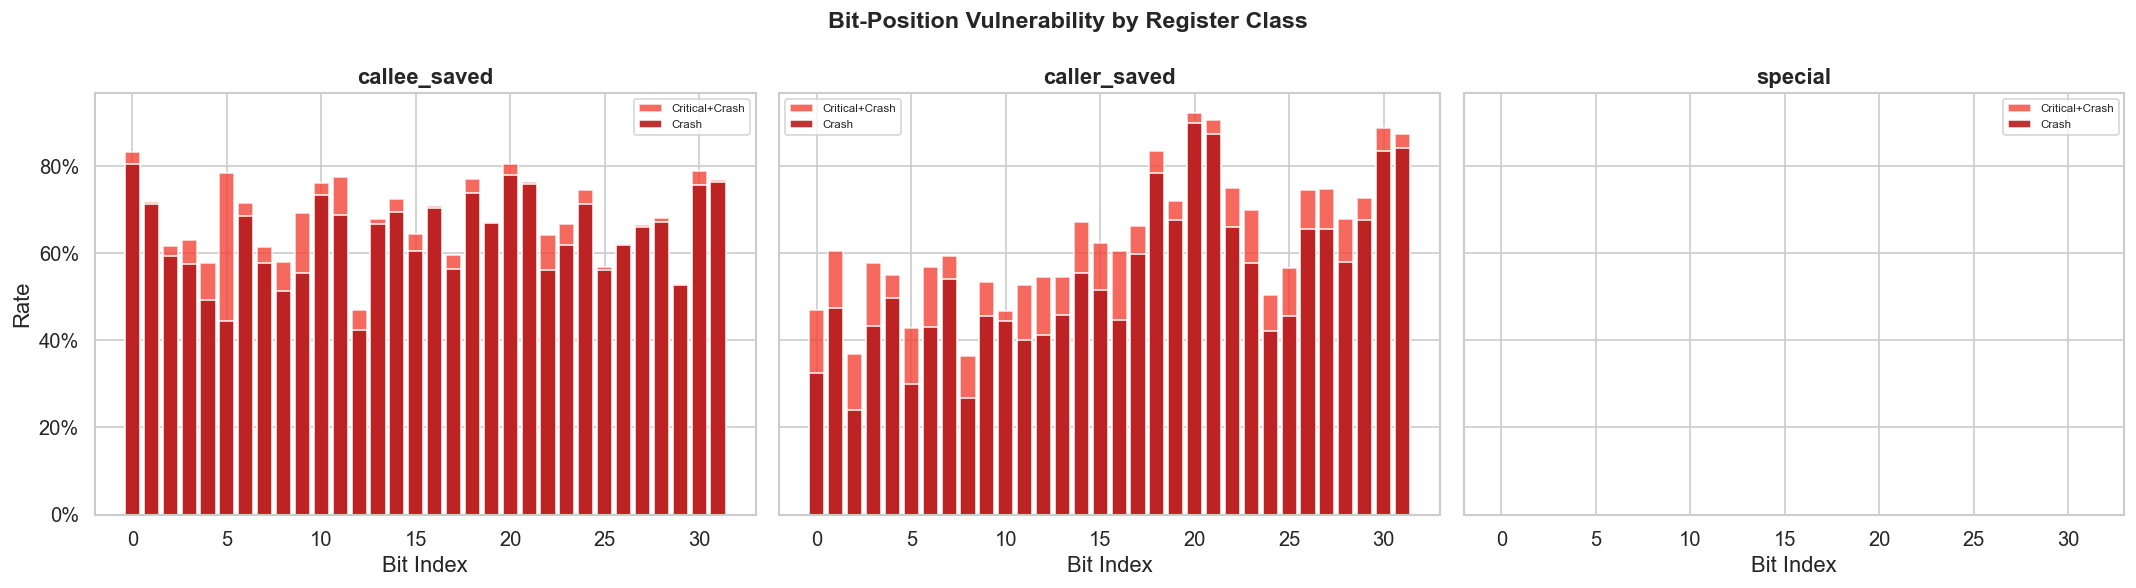

In [32]:
bit_cls = df.groupby(["register_class", "bit_index"]).apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0,
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g) if len(g) > 0 else 0,
    })
).reset_index()
bit_cls["bit_index"] = bit_cls["bit_index"].astype(int)

reg_classes = sorted(bit_cls["register_class"].unique())
fig, axes = plt.subplots(1, len(reg_classes), figsize=(6 * len(reg_classes), 5), sharey=True)
if len(reg_classes) == 1:
    axes = [axes]

for ax, rc in zip(axes, reg_classes):
    subset = bit_cls[bit_cls["register_class"] == rc].sort_values("bit_index")
    ax.bar(subset["bit_index"], subset["critical_rate"], color="#F44336", alpha=0.8, label="Critical+Crash")
    ax.bar(subset["bit_index"], subset["crash_rate"], color="#B71C1C", alpha=0.9, label="Crash")
    ax.set_title(f"{rc}", fontweight="bold")
    ax.set_xlabel("Bit Index")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.legend(fontsize=7)

axes[0].set_ylabel("Rate")
fig.suptitle("Bit-Position Vulnerability by Register Class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability_by_class.png", bbox_inches="tight")
plt.show()

## 9. Crash & Critical Failure Deep-Dive

Total critical/crash inferences: 164,189 (59.06%)
Unique faults causing critical/crash: 1976 / 2780



fault_class,Crash,Critical,total_critical
register_name,,,
a2,8797,89,8886
a0,8560,5,8565
a1,7898,569,8467
ra,7998,0,7998
a5,6564,1135,7699
s6,7241,437,7678
s0,7385,280,7665
s8,6699,614,7313
a7,5899,856,6755


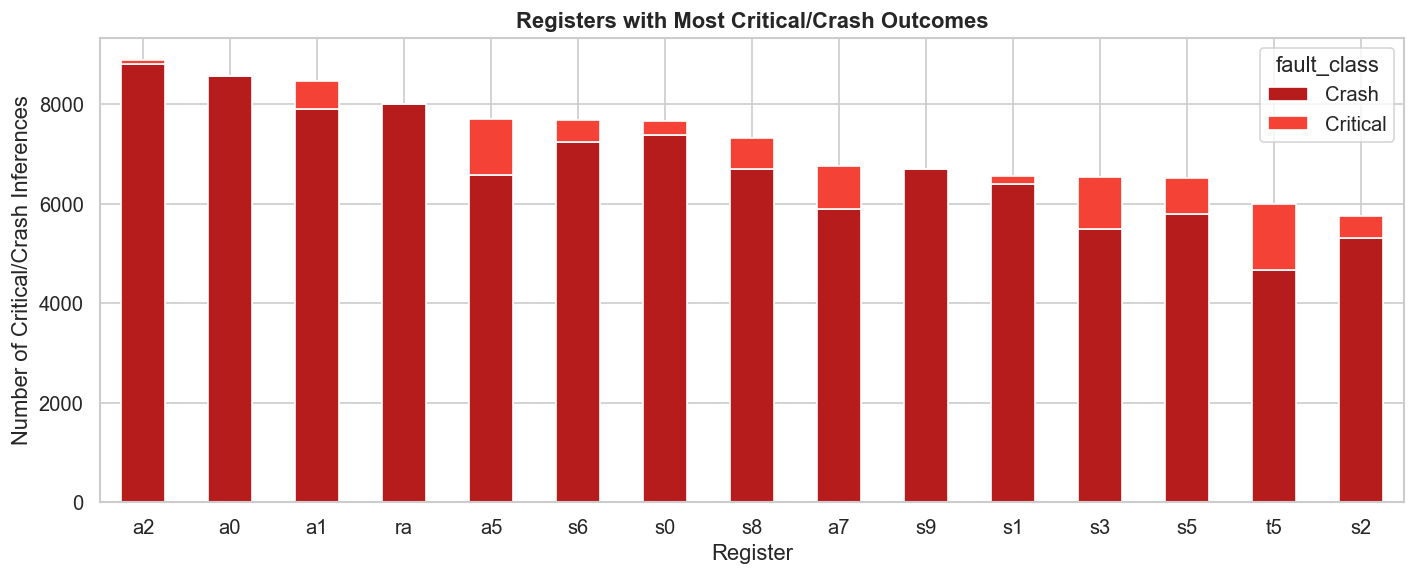

In [33]:
crit_df = df[df["fault_class"].isin(CRITICAL_SET)].copy()
print(f"Total critical/crash inferences: {len(crit_df):,} ({len(crit_df)/len(df)*100:.2f}%)")
print(f"Unique faults causing critical/crash: {crit_df['fault_id'].nunique()} / {df['fault_id'].nunique()}")
print()

# Which registers cause the most crashes?
crash_by_reg = crit_df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
crash_by_reg["total_critical"] = crash_by_reg.sum(axis=1)
crash_by_reg = crash_by_reg.sort_values("total_critical", ascending=False)
display(crash_by_reg.head(15))

# Top 10 most critical registers
fig, ax = plt.subplots(figsize=(12, 5))
top_crit_regs = crash_by_reg.head(15)
colors_stacked = []
for c in top_crit_regs.columns:
    if c == "total_critical":
        continue
    colors_stacked.append(SEVERITY_COLORS.get(c, "#999"))

plot_cols = [c for c in top_crit_regs.columns if c != "total_critical"]
top_crit_regs[plot_cols].plot.bar(stacked=True, ax=ax, color=colors_stacked, edgecolor="white")
ax.set_ylabel("Number of Critical/Crash Inferences")
ax.set_xlabel("Register")
ax.set_title("Registers with Most Critical/Crash Outcomes", fontweight="bold")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_crash_by_register.png", bbox_inches="tight")
plt.show()

## 10. Per-Fault Aggregated Vulnerability
For each unique fault injection, compute the fraction of images that were classified as critical/crash to identify the **most dangerous single-bit faults**.

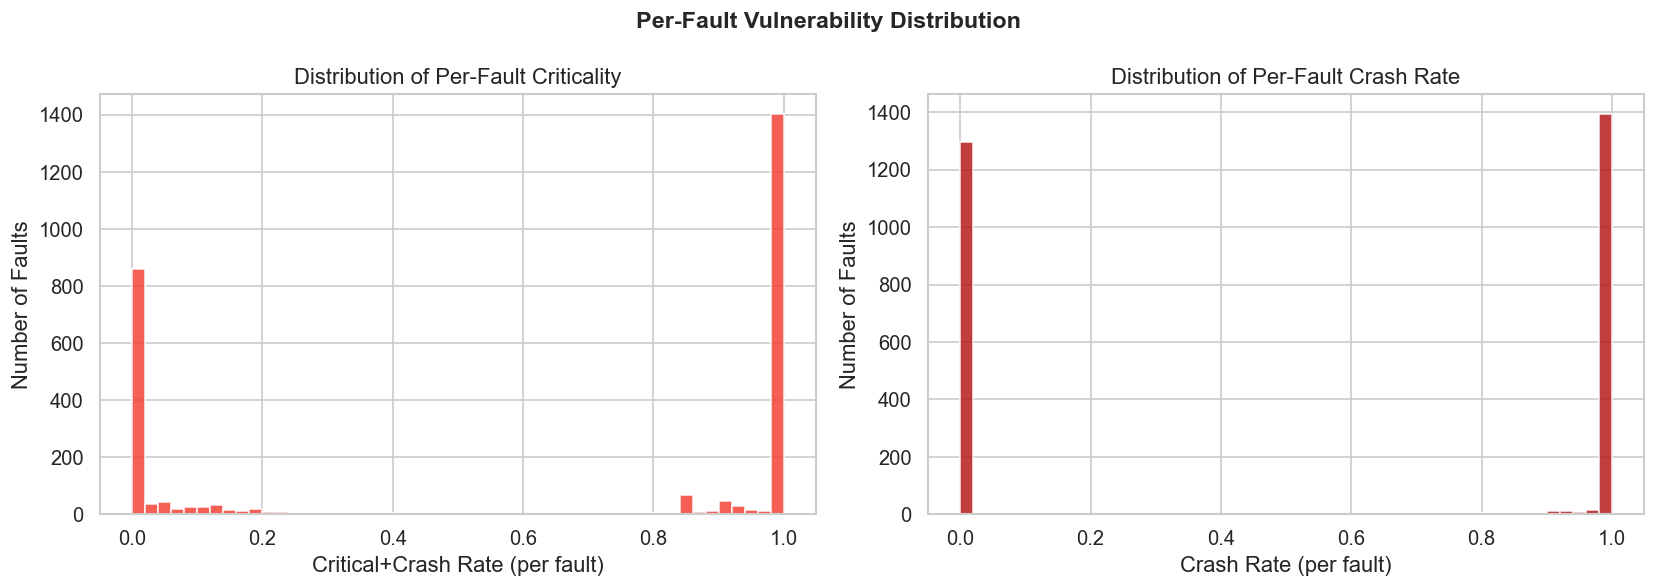


Top 20 most dangerous faults (by critical_rate):


,fault_id,register_name,register_class,bit_index,operator_index,operator_name,n_images,n_critical,n_crash,critical_rate,crash_rate
0,3.0,ra,caller_saved,3,0,CONV_2D,100,100,100,1.0,1.0
1,15.0,ra,caller_saved,15,0,CONV_2D,100,100,100,1.0,1.0
2,16.0,ra,caller_saved,16,0,CONV_2D,100,100,100,1.0,1.0
3,25.0,ra,caller_saved,25,0,CONV_2D,100,100,100,1.0,1.0
4,29.0,ra,caller_saved,29,0,CONV_2D,100,100,100,1.0,1.0
5,30.0,ra,caller_saved,30,0,CONV_2D,100,100,100,1.0,1.0
39,159.0,t0,caller_saved,31,0,CONV_2D,100,100,100,1.0,1.0
49,209.0,t2,caller_saved,17,0,CONV_2D,100,100,100,1.0,1.0
50,212.0,t2,caller_saved,20,0,CONV_2D,100,100,100,1.0,1.0
53,220.0,t2,caller_saved,28,0,CONV_2D,100,100,100,1.0,1.0


In [34]:
fault_agg = df.groupby("fault_id").apply(
    lambda g: pd.Series({
        "register_name": g["register_name"].iloc[0],
        "register_class": g["register_class"].iloc[0],
        "bit_index": int(g["bit_index"].iloc[0]),
        "operator_index": int(g["operator_index"].iloc[0]),
        "operator_name": g["operator_name"].iloc[0] if "operator_name" in g.columns else "",
        "n_images": len(g),
        "n_critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "n_crash": (g["fault_class"] == "Crash").sum(),
        "n_masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g),
    })
).reset_index()

# Distribution of per-fault critical rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fault_agg["critical_rate"], bins=50, color="#F44336", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Critical+Crash Rate (per fault)")
axes[0].set_ylabel("Number of Faults")
axes[0].set_title("Distribution of Per-Fault Criticality")

axes[1].hist(fault_agg["crash_rate"], bins=50, color="#B71C1C", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Crash Rate (per fault)")
axes[1].set_ylabel("Number of Faults")
axes[1].set_title("Distribution of Per-Fault Crash Rate")

fig.suptitle("Per-Fault Vulnerability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_per_fault_distribution.png", bbox_inches="tight")
plt.show()

# Top 20 most dangerous faults
print("\nTop 20 most dangerous faults (by critical_rate):")
display(fault_agg.nlargest(20, "critical_rate")[
    ["fault_id", "register_name", "register_class", "bit_index",
     "operator_index", "operator_name", "n_images", "n_critical",
     "n_crash", "critical_rate", "crash_rate"]
])

## 11. Confidence Interval Estimation
Using Wilson score intervals for binomial proportions.

,register,n,critical_rate,critical_CI_lo,critical_CI_hi,crash_rate,crash_CI_lo,crash_CI_hi
0,a1,8800,0.9622,0.9580,0.9659,0.8975,0.8910,0.9037
1,ra,8800,0.9089,0.9027,0.9147,0.9089,0.9027,0.9147
2,a0,9500,0.9016,0.8954,0.9074,0.9011,0.8949,0.9069
3,a2,10100,0.8798,0.8733,0.8860,0.8710,0.8643,0.8774
4,s0,8800,0.8710,0.8639,0.8779,0.8392,0.8314,0.8467
5,a5,9100,0.8460,0.8385,0.8533,0.7213,0.7120,0.7304
6,s6,9700,0.7915,0.7833,0.7995,0.7465,0.7377,0.7551
7,s8,9400,0.7780,0.7695,0.7863,0.7127,0.7034,0.7217
8,s3,8400,0.7773,0.7682,0.7860,0.6536,0.6433,0.6637
9,s9,8900,0.7528,0.7437,0.7617,0.7528,0.7437,0.7617


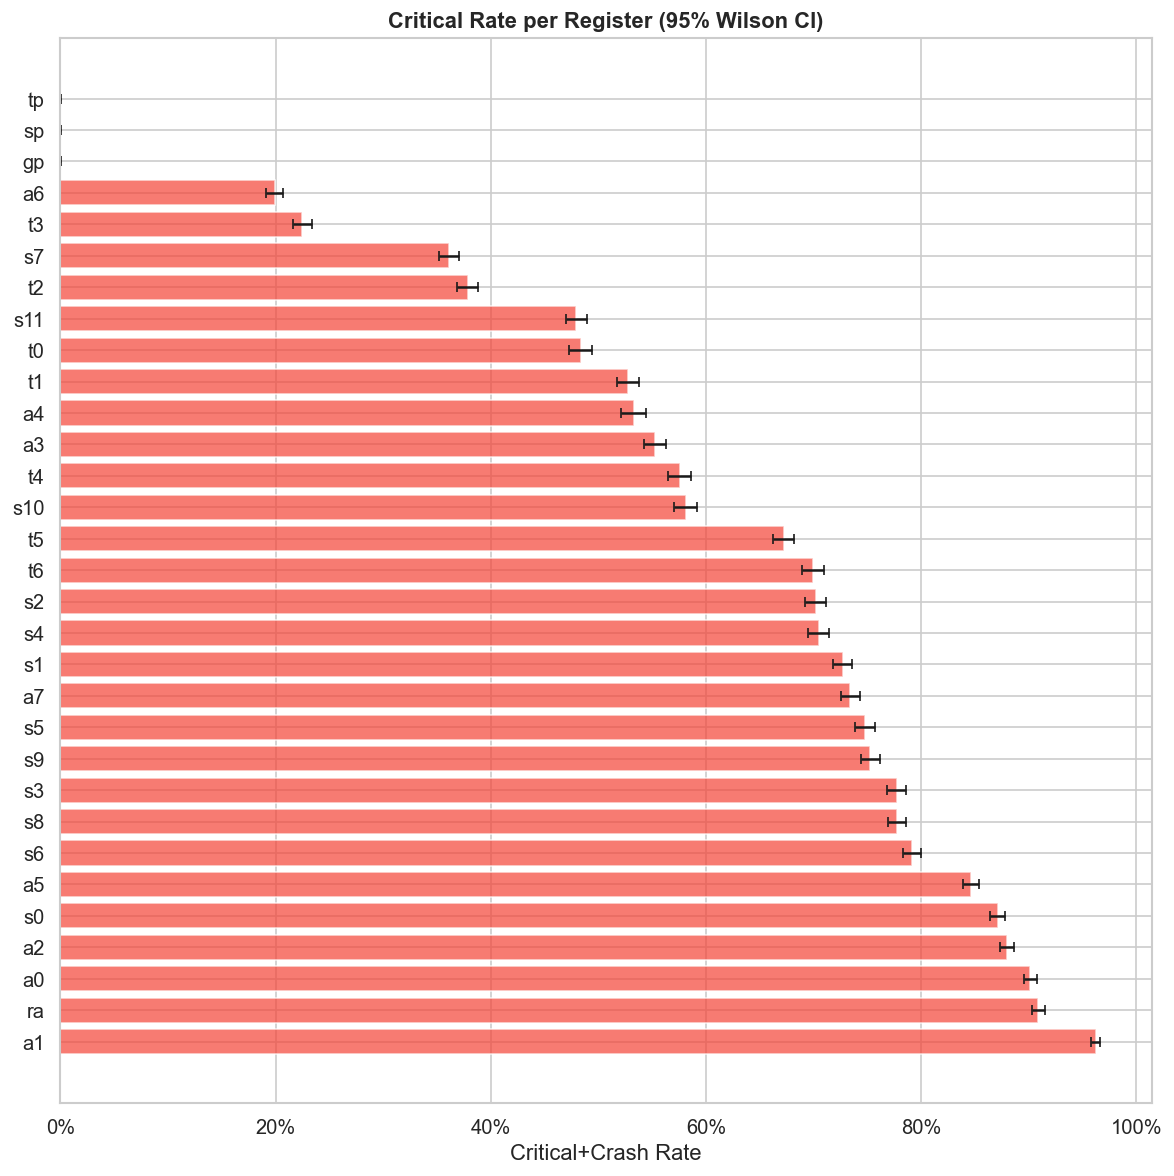

In [35]:
def wilson_ci(successes, total, confidence=0.95):
    """Wilson score confidence interval for a binomial proportion."""
    if total == 0:
        return 0.0, 0.0, 0.0
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p_hat = successes / total
    denom = 1 + z**2 / total
    center = (p_hat + z**2 / (2 * total)) / denom
    margin = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * total)) / total) / denom
    return p_hat, max(0, center - margin), min(1, center + margin)

# CI per register
ci_rows = []
for reg, grp in df.groupby("register_name"):
    n = len(grp)
    n_crit = grp["fault_class"].isin(CRITICAL_SET).sum()
    n_crash = (grp["fault_class"] == "Crash").sum()
    p_crit, lo_crit, hi_crit = wilson_ci(n_crit, n)
    p_crash, lo_crash, hi_crash = wilson_ci(n_crash, n)
    ci_rows.append({
        "register": reg,
        "n": n,
        "critical_rate": p_crit,
        "critical_CI_lo": lo_crit,
        "critical_CI_hi": hi_crit,
        "crash_rate": p_crash,
        "crash_CI_lo": lo_crash,
        "crash_CI_hi": hi_crash,
    })

ci_df = pd.DataFrame(ci_rows).sort_values("critical_rate", ascending=False).reset_index(drop=True)
display(ci_df.round(4))

# Forest plot of CI
fig, ax = plt.subplots(figsize=(10, 10))
y_pos = np.arange(len(ci_df))
ax.barh(y_pos, ci_df["critical_rate"], xerr=[
    ci_df["critical_rate"] - ci_df["critical_CI_lo"],
    ci_df["critical_CI_hi"] - ci_df["critical_rate"]
], color="#F44336", alpha=0.7, capsize=3, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(ci_df["register"])
ax.set_xlabel("Critical+Crash Rate")
ax.set_title("Critical Rate per Register (95% Wilson CI)", fontweight="bold")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_ci_per_register.png", bbox_inches="tight")
plt.show()

## 12. Register × Bit Heatmap (Critical Rate)

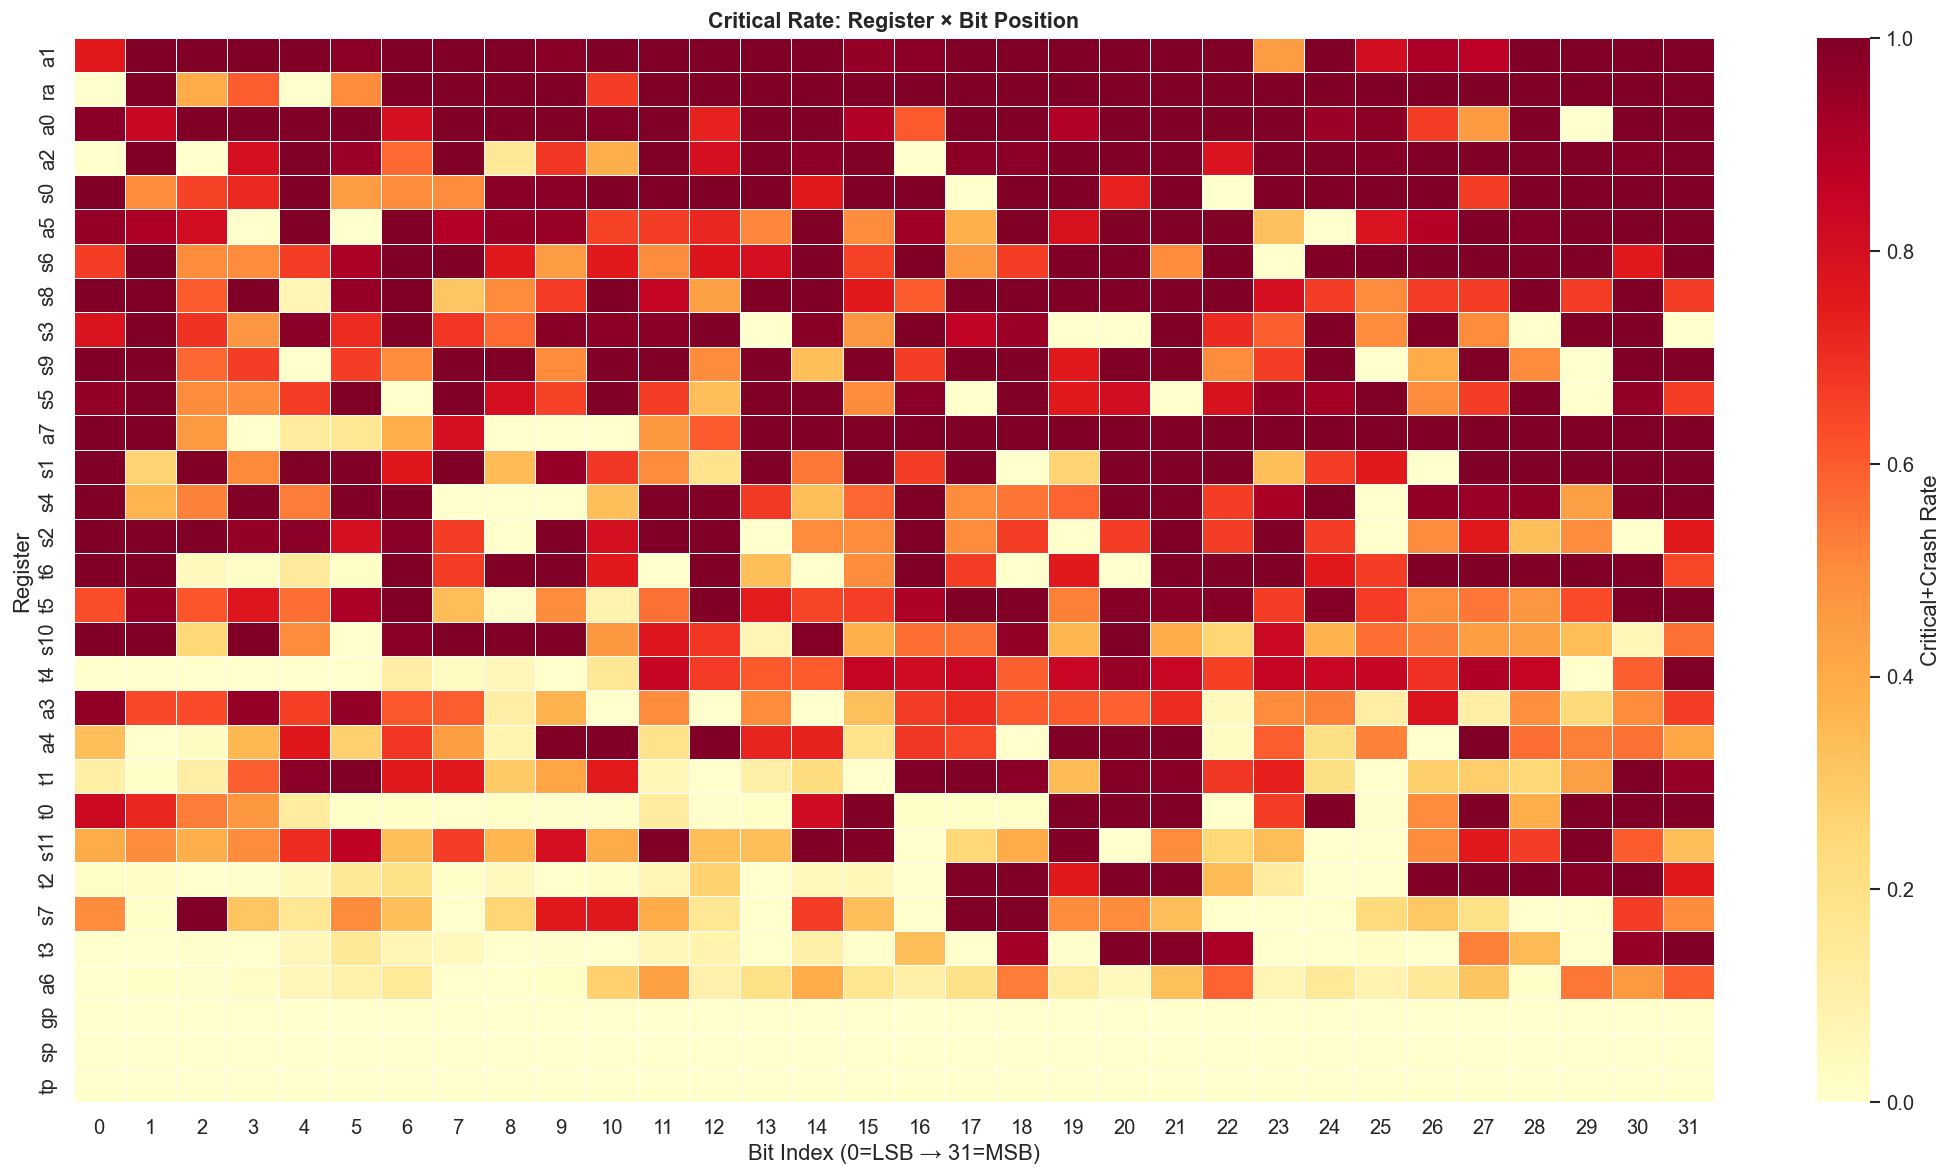

In [36]:
reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)
reg_bit_crit = reg_bit_crit.reindex(reg_order)
reg_bit_crit.columns = reg_bit_crit.columns.astype(int)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    reg_bit_crit, cmap="YlOrRd", linewidths=0.3, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical+Crash Rate"},
    vmin=0, vmax=max(reg_bit_crit.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Bit Position", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Bit Index (0=LSB → 31=MSB)")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_bit.png", bbox_inches="tight")
plt.show()

## 13. Impact on Model Accuracy
Compare the **golden accuracy** (no fault) against the effective accuracy under each fault scenario.

Golden Accuracy : 0.0332 (3.32%)
Faulty Accuracy : 0.0364 (3.64%)
Accuracy Drop   : -0.32 pp


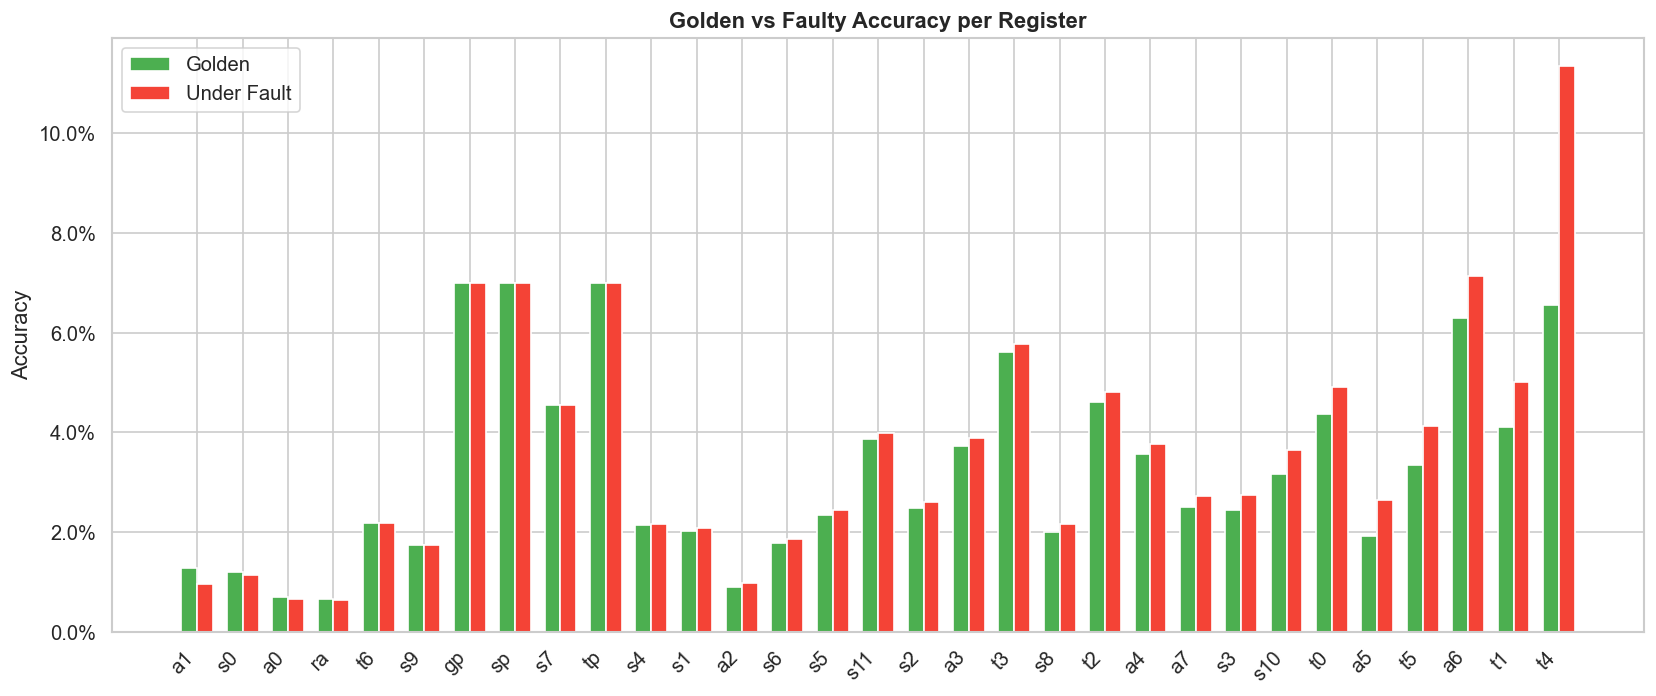

,faulty_accuracy,golden_accuracy,accuracy_drop
register_name,,,
a1,0.0095,0.0128,0.0033
s0,0.0114,0.0119,0.0006
a0,0.0065,0.0069,0.0004
ra,0.0064,0.0066,0.0002
t6,0.0217,0.0219,0.0001
s9,0.0173,0.0173,0.0000
gp,0.0700,0.0700,0.0000
sp,0.0700,0.0700,0.0000
s7,0.0456,0.0456,0.0000


In [37]:
# Golden accuracy
golden_correct = (df["golden_pred_class_ref"] == df["label"]).sum()
golden_acc = golden_correct / len(df)

# Faulty accuracy
faulty_correct = (df["pred_class"] == df["label"]).sum()
faulty_acc = faulty_correct / len(df)

print(f"Golden Accuracy : {golden_acc:.4f} ({golden_acc*100:.2f}%)")
print(f"Faulty Accuracy : {faulty_acc:.4f} ({faulty_acc*100:.2f}%)")
print(f"Accuracy Drop   : {(golden_acc - faulty_acc)*100:.2f} pp")

# Accuracy per register
acc_per_reg = df.groupby("register_name").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": ((g["golden_pred_class_ref"] == g["label"]).sum() - (g["pred_class"] == g["label"]).sum()) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(acc_per_reg))
w = 0.35
ax.bar(x - w/2, acc_per_reg["golden_accuracy"], w, label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_reg["faulty_accuracy"], w, label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_reg.index, rotation=45, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Golden vs Faulty Accuracy per Register", fontweight="bold")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_accuracy_per_register.png", bbox_inches="tight")
plt.show()

display(acc_per_reg.round(4))

## 14. Probability (Confidence) Degradation Analysis
For non-crash inferences, measure how fault injection affected the output confidence.

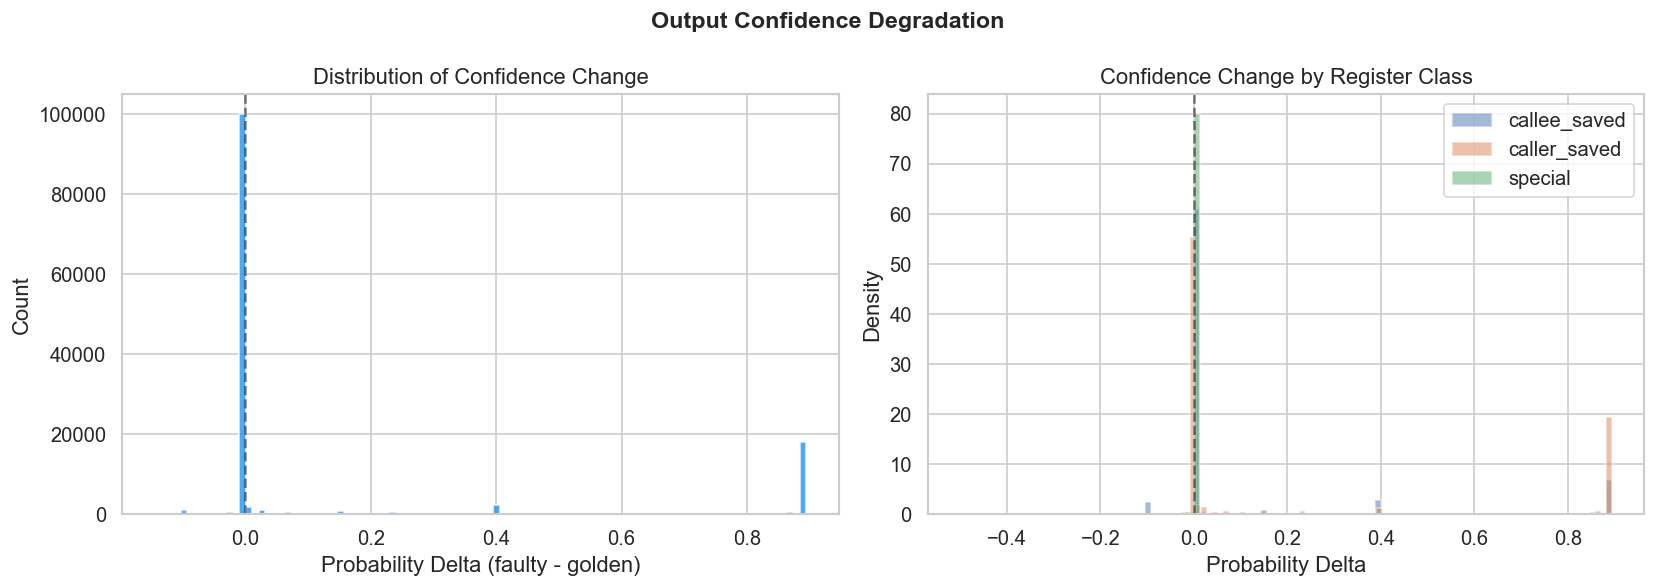

,mean,std,min,max
register_name,,,,
ra,0.0000,0.0000,0.0000,0.0000
gp,0.0000,0.0000,0.0000,0.0000
s9,0.0000,0.0000,0.0000,0.0000
sp,0.0000,0.0000,0.0000,0.0000
tp,0.0000,0.0000,0.0000,0.0000
a0,0.0038,0.0480,0.0000,0.8945
s7,0.0099,0.0742,-0.0234,0.8945
a4,0.0260,0.1413,-0.0430,0.8945
t3,0.0283,0.1465,-0.0430,0.8945


In [38]:
ok_df = df[df["status"] == "ok"].copy()
ok_df["prob_delta"] = ok_df["top1_prob"] - ok_df["golden_top1_prob_ref"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ok_df["prob_delta"], bins=100, color="#2196F3", edgecolor="white", alpha=0.8)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Probability Delta (faulty - golden)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Confidence Change")

# Per register class
for rc in sorted(ok_df["register_class"].dropna().unique()):
    subset = ok_df[ok_df["register_class"] == rc]["prob_delta"]
    axes[1].hist(subset, bins=80, alpha=0.5, label=rc, density=True)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Probability Delta")
axes[1].set_ylabel("Density")
axes[1].set_title("Confidence Change by Register Class")
axes[1].legend()

fig.suptitle("Output Confidence Degradation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_confidence_degradation.png", bbox_inches="tight")
plt.show()

# Mean confidence delta per register
prob_stats = ok_df.groupby("register_name")["prob_delta"].agg(["mean", "std", "min", "max"]).sort_values("mean")
display(prob_stats.round(4))

## 15. Summary Table (LaTeX-ready)
Consolidated table for the paper.

In [39]:
# Build per-register summary
summary_rows = []
for reg, grp in df.groupby("register_name"):
    n = len(grp)
    reg_class = grp["register_class"].iloc[0] if "register_class" in grp.columns else "?"
    fc = grp["fault_class"].value_counts()
    n_masked = fc.get("Masked", 0)
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    n_crash = fc.get("Crash", 0)
    acc = (grp["pred_class"] == grp["label"]).sum() / n
    p_crit, lo, hi = wilson_ci(n_crit, n)
    summary_rows.append({
        "Register": reg,
        "Class": reg_class,
        "N": n,
        "Masked %": round(n_masked / n * 100, 2),
        "Critical %": round(n_crit / n * 100, 2),
        "Crash %": round(n_crash / n * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
        "Accuracy %": round(acc * 100, 2),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Critical %", ascending=False).reset_index(drop=True)
display(summary_df)

# Overall
overall_n = len(df)
overall_fc = df["fault_class"].value_counts()
overall_crit = overall_fc.get("Critical", 0) + overall_fc.get("Crash", 0)
p, lo, hi = wilson_ci(overall_crit, overall_n)
print(f"\nOverall Critical+Crash Rate: {p*100:.2f}% [95% CI: {lo*100:.2f}% – {hi*100:.2f}%]")
print(f"Total faults sampled: {df['fault_id'].nunique()} / {len(pop)} population")

# LaTeX export
latex_str = summary_df.to_latex(index=False, float_format="%.2f", caption="Register fault injection resilience summary.", label="tab:register_resilience")
print("\n--- LaTeX Table ---")
print(latex_str)

,Register,Class,N,Masked %,Critical %,Crash %,CI 95% low,CI 95% high,Accuracy %
0,a1,caller_saved,8800,1.05,96.22,89.75,95.80,96.59,0.95
1,ra,caller_saved,8800,9.11,90.89,90.89,90.27,91.47,0.64
2,a0,caller_saved,9500,9.80,90.16,90.11,89.54,90.74,0.65
3,a2,caller_saved,10100,11.41,87.98,87.10,87.33,88.60,0.97
4,s0,callee_saved,8800,6.16,87.10,83.92,86.39,87.79,1.14
5,a5,caller_saved,9100,8.24,84.60,72.13,83.85,85.33,2.64
6,s6,callee_saved,9700,19.53,79.15,74.65,78.33,79.95,1.86
7,s8,callee_saved,9400,17.90,77.80,71.27,76.95,78.63,2.17
8,s3,callee_saved,8400,12.85,77.73,65.36,76.82,78.60,2.75
9,s9,callee_saved,8900,24.72,75.28,75.28,74.37,76.17,1.73



Overall Critical+Crash Rate: 59.06% [95% CI: 58.88% – 59.24%]
Total faults sampled: 2780 / 9920 population


ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.

## 16. Per Register-Class Summary (LaTeX-ready)

In [ ]:
cls_summary = []
for rc, grp in df.groupby("register_class"):
    n = len(grp)
    fc = grp["fault_class"].value_counts()
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    p, lo, hi = wilson_ci(n_crit, n)
    cls_summary.append({
        "Register Class": rc,
        "N": n,
        "Masked %": round(fc.get("Masked", 0) / n * 100, 2),
        "Acceptable %": round(fc.get("Acceptable", 0) / n * 100, 2),
        "Warning %": round(fc.get("Warning", 0) / n * 100, 2),
        "Critical %": round(fc.get("Critical", 0) / n * 100, 2),
        "Crash %": round(fc.get("Crash", 0) / n * 100, 2),
        "Crit+Crash %": round(p * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
    })

cls_summary_df = pd.DataFrame(cls_summary).sort_values("Crit+Crash %", ascending=False).reset_index(drop=True)
display(cls_summary_df)

latex_cls = cls_summary_df.to_latex(index=False, float_format="%.2f", caption="Resilience by RISC-V register class.", label="tab:register_class_resilience")
print("\n--- LaTeX Table ---")
print(latex_cls)

## 17. Export Analysis Artifacts

In [ ]:
export_dir = RUN_DIR / "notebook_exports"
export_dir.mkdir(exist_ok=True)

summary_df.to_csv(export_dir / "summary_per_register.csv", index=False)
cls_summary_df.to_csv(export_dir / "summary_per_register_class.csv", index=False)
ci_df.to_csv(export_dir / "confidence_intervals.csv", index=False)
bit_fc.to_csv(export_dir / "bit_vulnerability.csv", index=False)
fault_agg.to_csv(export_dir / "per_fault_aggregated.csv", index=False)
reg_fc.to_csv(export_dir / "classification_per_register.csv")
op_fc.to_csv(export_dir / "classification_per_operator.csv")

print(f"Exported {len(list(export_dir.glob('*')))} files to {export_dir}")
for f in sorted(export_dir.glob("*")):
    print(f"  {f.name} ({f.stat().st_size:,} bytes)")